In [81]:
import pandas as pd
import numpy as np
import xarray as xr

import matplotlib.pyplot as plt

from utils.tv_var.periodic_var import PeriodicVAR, select_order

import pickle
from utils.pit.piece_wise_marginal import from_normal

In [82]:
point = 'p102'

waves_df = pd.read_csv(f"inputs/waves_bulk_{point}.csv", index_col=0, parse_dates=True)
tr_ = pickle.load(open(f"outputs/marginal/transformacion_{point}.pkl", "rb"))
marg, harm_z = tr_["marg"], tr_["harm_z"]

def hs_desde_z(z):
    """Serie de Z (Hs) → Hs en metros, deshaciendo la armónica, Φ y la marginal."""
    zz = pd.DataFrame({"VHM0": z, "VTM02": 0.0}, index=z.index)      # la armónica se ajustó con las dos columnas
    z0 = harm_z.inverse_transform(zz)["VHM0"].clip(-6.36, 6.36)    # mismo límite que to_normal (eps=1e-10)
    return pd.Series(marg["VHM0"].ppf(from_normal(z0).values), index=z.index)

In [83]:
resid = pd.read_csv(f"outputs/xgb_pit_{point}/residuos_horarios.csv", index_col=0, parse_dates=True)
hs_obs = waves_df.loc["2016":"2025", "VHM0"]

#### Suavizado de f (media móvil centrada): quita el ruido de estimación del XGB antes de añadir el residuo
SIMPLIFICADO = True
SUAVIZADO_H = 1 if SIMPLIFICADO else 13

if SUAVIZADO_H > 1:
    resid["f"] = resid["f"].rolling(SUAVIZADO_H, center=True, min_periods=1).mean()
    resid["r"] = resid["z"] - resid["f"]
print(f"std r oof {resid.loc[resid.periodo == 'oof', 'r'].std():.3f} | test {resid.loc[resid.periodo == 'test', 'r'].std():.3f}")

std r oof 0.627 | test 0.619


In [84]:
#### Modelo de escala: r = σ(f) · u, con u un VAR homocedástico
#### σ(f) = desviación de r_oof por decil de f (bordes de entrenamiento, se reutilizan al simular)
r_oof = resid.loc[resid.periodo == "oof", ["r"]].asfreq("h")          # malla horaria completa (huecos = NaN)
f_oof = resid["f"].reindex(r_oof.index)

bordes = np.quantile(f_oof.dropna(), np.linspace(0, 1, 11)[1:-1])     # 9 bordes → 10 deciles
dec_oof = pd.Series(np.digitize(f_oof, bordes), index=r_oof.index).where(f_oof.notna())   # 0 … 9
sigma = r_oof["r"].groupby(dec_oof).std()
sigma.index = sigma.index.astype(int)

if SIMPLIFICADO:
    sigma[:] = 1.0   

#### Comparar con el residuo real de test (debería parecerse: 0.64 → 0.52)
r_test = resid.loc[resid.periodo == "test", ["r", "f"]]
sigma_test = r_test["r"].groupby(np.digitize(r_test["f"], bordes)).std()
print(pd.DataFrame({"σ oof": sigma, "σ test": sigma_test}, index=range(10)).set_axis(range(1, 11)).round(3).T)

           1      2      3     4      5      6      7      8      9      10
σ oof   1.000  1.000  1.000  1.00  1.000  1.000  1.000  1.000  1.000  1.000
σ test  0.683  0.683  0.638  0.64  0.626  0.606  0.604  0.578  0.546  0.525


In [85]:
#### Residuo estandarizado u = r / σ(decil)
sig_oof = dec_oof.map(sigma)
u_oof = r_oof.div(sig_oof, axis=0)                                    # misma columna "r"
print(u_oof["r"].groupby(dec_oof).std().round(3).values)              # todo ≈ 1

[0.687 0.681 0.658 0.657 0.628 0.634 0.596 0.579 0.557 0.54 ]


In [86]:
select_order(u_oof, p_values=[12, 20, 24, 36, 48], n_harm=0, freq="h")

,nobs,loglike,n_params,bic,best
p,,,,,
12,271680,331360.271641,25,-662407.733777,False
20,271680,331694.452472,33,-662975.996398,False
24,271680,331720.685611,37,-662978.413155,False
36,271680,331811.259548,49,-663009.412467,False
48,271680,331975.533233,61,-663187.811275,True


In [87]:
results_u = PeriodicVAR(p=48, n_harm=0, freq="h").fit(u_oof)
print(results_u.nobs_, results_u.resid_.index[0], results_u.resid_.index[-1])

271680 1985-01-03 00:00:00 2015-12-31 23:00:00


In [88]:
#### ¿Innovaciones de u homocedásticas? Si sí → un solo pool
e_u = results_u.resid_["r"].asfreq("h")                               # innovaciones en malla horaria (huecos = NaN)
dec_e = np.digitize(resid["f"].reindex(e_u.index), bordes)
sd_e = e_u.groupby(dec_e).std().loc[0:9]
print(sd_e.round(3).values)
print(f"ratio decil 10 / decil 1: {sd_e.loc[9] / sd_e.loc[0]:.2f}  (≈ 1 → un pool basta)")
print(f"ACF de e² en lag 1: {(e_u**2).autocorr(1):.3f}  (< 0.1 → no hacen falta bloques)")

[0.079 0.074 0.071 0.072 0.07  0.071 0.071 0.071 0.07  0.069]
ratio decil 10 / decil 1: 0.87  (≈ 1 → un pool basta)
ACF de e² en lag 1: 0.381  (< 0.1 → no hacen falta bloques)


In [89]:
#### f de las PCs históricas en test (2016–2025), malla horaria continua, y su σ
f_sim = resid.loc["2016-01-01":"2025-12-31", "f"].asfreq("h")
print(f_sim.isna().sum())                       # debe ser 0; si no, f_sim = f_sim.interpolate()

dec_sim = np.digitize(f_sim, bordes)
sig_sim = pd.Series(sigma.loc[dec_sim].values, index=f_sim.index)
hs_f = hs_desde_z(f_sim)                        # f pasada a metros

0


In [90]:
#### Un solo pool de innovaciones, en bloques de L horas (L = 1 → hora a hora)
L = 1 if SIMPLIFICADO else 6
ev = e_u.values
completo = np.convolve(~np.isnan(ev), np.ones(L), "valid") == L       # L innovaciones seguidas sin huecos
inicios = np.flatnonzero(completo)
print(len(inicios))

def ruido_bloques(n, L, rng):
    out = np.empty(n)
    t = 0
    while t < n:
        s = rng.choice(inicios)
        m = min(L, n - t)
        out[t:t + m] = ev[s:s + m]
        t += m
    return out

271680


In [91]:
#### Mapeo de cuantiles por decil: r_sim toma la forma (std y asimetría) de r_oof de su decil
#### (necesita dec_oof de la celda de σ y dec_sim de la celda de f_sim)
MAPEO = False                                                          # False → 05C original (solo escala)
pools_r = {k: np.sort(r_oof["r"][dec_oof == k].dropna().values) for k in range(10)}

def mapear(r):
    out = np.empty(len(r))
    for k in range(10):
        m = dec_sim == k
        rk = (pd.Series(r.values[m]).rank().values - 0.5) / m.sum()     # rango dentro del decil
        out[m] = np.quantile(pools_r[k], rk)
    return pd.Series(out, index=r.index)

In [92]:
import time
n_sims = 50
hs_sims, r_sims = [], []

for i in range(n_sims):
    t = time.time()
    rng = np.random.default_rng(i)
    ruido_df = pd.DataFrame(ruido_bloques(len(f_sim), L, rng), index=f_sim.index, columns=["r"])
    u_i = results_u.simulate(noise=ruido_df, burn=24*30)["r"]
    r_i = u_i * sig_sim                                       # ← la escala se aplica en t, no en la innovación
    if MAPEO:
        r_i = mapear(r_i)                                     # ← forma de r_oof en cada decil
    hs_sims.append(hs_desde_z(f_sim + r_i))
    r_sims.append(r_i)
    print(f"sim {i:02d} ({time.time() - t:.0f} s)")

hs_sims = pd.concat(hs_sims, axis=1)                         # (horas, n_sims)
r_sims = pd.concat(r_sims, axis=1)

sim 00 (2 s)
sim 01 (2 s)
sim 02 (2 s)
sim 03 (2 s)
sim 04 (2 s)
sim 05 (2 s)
sim 06 (2 s)
sim 07 (2 s)
sim 08 (2 s)
sim 09 (2 s)
sim 10 (2 s)
sim 11 (2 s)
sim 12 (2 s)
sim 13 (2 s)
sim 14 (2 s)
sim 15 (2 s)
sim 16 (2 s)
sim 17 (2 s)
sim 18 (2 s)
sim 19 (2 s)
sim 20 (2 s)
sim 21 (2 s)
sim 22 (2 s)
sim 23 (2 s)
sim 24 (2 s)
sim 25 (2 s)
sim 26 (2 s)
sim 27 (2 s)
sim 28 (2 s)
sim 29 (2 s)
sim 30 (2 s)
sim 31 (2 s)
sim 32 (2 s)
sim 33 (2 s)
sim 34 (2 s)
sim 35 (2 s)
sim 36 (2 s)
sim 37 (2 s)
sim 38 (2 s)
sim 39 (2 s)
sim 40 (2 s)
sim 41 (2 s)
sim 42 (2 s)
sim 43 (3 s)
sim 44 (3 s)
sim 45 (3 s)
sim 46 (3 s)
sim 47 (3 s)
sim 48 (3 s)
sim 49 (3 s)


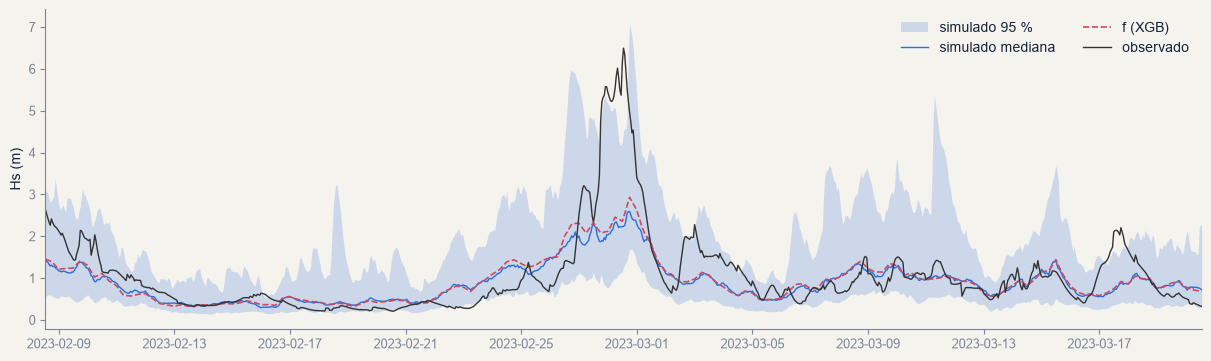

In [93]:
t_max = hs_obs.idxmax()
t0, t1 = t_max - pd.Timedelta(days=20), t_max + pd.Timedelta(days=20)

w = hs_sims.loc[t0:t1]
lo, med, hi = w.quantile(0.025, axis=1), w.median(axis=1), w.quantile(0.975, axis=1)

fig, ax = plt.subplots(figsize=(12, 3.5), constrained_layout=True)
ax.fill_between(w.index, lo, hi, color="#2a6fdb", alpha=0.2, lw=0, label="simulado 95 %")
ax.plot(med, color="#2a6fdb", lw=1, label="simulado mediana")
ax.plot(hs_f.loc[t0:t1], color="#d1495b", lw=1.2, ls="--", label="f (XGB)")
ax.plot(hs_obs.loc[t0:t1], color="0.2", lw=1, label="observado")
ax.set(ylabel="Hs (m)", xlim=(t0, t1))
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False, loc="upper right", ncol=2)
plt.show()

In [94]:
#### Cobertura y cuantiles altos
q_lo, q_hi = hs_sims.quantile(0.025, axis=1), hs_sims.quantile(0.975, axis=1)
o = hs_obs.reindex(hs_sims.index)
print(f"por encima {(o > q_hi).mean():.1%} | por debajo {(o < q_lo).mean():.1%}  (esperado 2,5 %)")

st = pd.DataFrame({"q99": hs_sims.quantile(0.99), "q999": hs_sims.quantile(0.999), "max": hs_sims.max()})
print(f"obs: q99 {hs_obs.quantile(0.99):.2f} | q999 {hs_obs.quantile(0.999):.2f} | max {hs_obs.max():.2f}")
print(st.quantile([0.025, 0.5, 0.975]).round(2))

por encima 3.8% | por debajo 4.9%  (esperado 2,5 %)
obs: q99 3.56 | q999 5.06 | max 6.49
        q99  q999    max
0.025  4.06  5.82   7.42
0.500  4.25  6.44   8.79
0.975  4.48  7.00  10.93


In [95]:
#### Desviación del residuo, real vs simulado, por decil de f (en test)
d = pd.DataFrame({"f": f_sim, "r_real": resid["r"].reindex(f_sim.index)})
d["decil"] = np.digitize(d["f"], bordes) + 1
tabla = pd.DataFrame({"r_real": d.groupby("decil")["r_real"].std(),
                      "r_sim": r_sims.groupby(d["decil"]).std().median(axis=1)})   # mediana de las 50 sims
print(tabla.round(3).T)

from scipy.stats import skew
print("asimetría real:", d.groupby("decil")["r_real"].apply(lambda x: skew(x.dropna())).round(2).values)
print("asimetría sim :", r_sims.iloc[:, 0].groupby(d["decil"]).apply(skew).round(2).values)

decil      1     2      3      4      5      6      7      8      9      10
r_real  0.680  0.67  0.633  0.637  0.623  0.600  0.596  0.577  0.544  0.527
r_sim   0.617  0.62  0.624  0.625  0.626  0.628  0.624  0.628  0.628  0.623
asimetría real: [-0.11 -0.31 -0.33 -0.19 -0.04 -0.12 -0.13 -0.06 -0.14 -0.01]
asimetría sim : [0.51 0.88 0.39 0.36 0.5  0.4  0.53 0.38 0.09 0.2 ]


In [96]:
from scipy.signal import find_peaks

def picos(serie, umbral, sep_h=72):
    pk, _ = find_peaks(serie.values, height=umbral, distance=sep_h)
    return serie.iloc[pk].values

u = hs_obs.quantile(0.99)
p_obs = picos(hs_obs, u)
p_sim = [picos(hs_sims[c], u) for c in hs_sims.columns]
n_sim = [len(p) for p in p_sim]

print(f"nº temporales: obs {len(p_obs)} | sim {np.median(n_sim):.0f} "
      f"[{np.percentile(n_sim, 2.5):.0f}–{np.percentile(n_sim, 97.5):.0f}]")
for q in [0.5, 0.9]:
    qs = [np.quantile(p, q) for p in p_sim]
    print(f"pico q{int(q*100)}: obs {np.quantile(p_obs, q):.2f} | sim {np.median(qs):.2f} "
          f"[{np.percentile(qs, 2.5):.2f}–{np.percentile(qs, 97.5):.2f}]")

nº temporales: obs 65 | sim 95 [78–109]
pico q50: obs 4.14 | sim 4.52 [4.32–4.71]
pico q90: obs 5.42 | sim 6.40 [5.81–6.90]


In [97]:
#### ¿En qué decil de f caen los picos simulados? (sim 0)
pk, _ = find_peaks(hs_sims.iloc[:, 0].values, height=u, distance=72)
print(pd.Series(np.digitize(f_sim.iloc[pk], bordes) + 1).value_counts().sort_index())

2      2
4      2
5      3
6      2
7      4
8      9
9     17
10    63
Name: count, dtype: int64


In [98]:
#### Exportar lo necesario para simular en otros notebooks (XX_TEST)
nombre = "escala_simple" if SIMPLIFICADO else "escala.pkl"
pickle.dump({"bordes": bordes, "sigma": sigma, "pools_r": pools_r, "results_u": results_u, "L": L, "suavizado_h": SUAVIZADO_H},
            open(f"outputs/xgb_pit_{point}/{nombre}.pkl", "wb"))

In [99]:
import os
from scipy.stats import skew
from scipy.signal import find_peaks
os.makedirs("figuras", exist_ok=True)

TINTA, AZUL, NARANJA, GRIS, FONDO = "#13233A", "#2C6E91", "#C8622A", "#7A8594", "#F5F3EE"
plt.rcParams.update({
    "font.family": "sans-serif", "font.sans-serif": ["Inter", "Arial", "DejaVu Sans"],
    "font.size": 10, "axes.titlesize": 11, "axes.labelsize": 10, "xtick.labelsize": 9, "ytick.labelsize": 9,
    "axes.edgecolor": GRIS, "axes.labelcolor": TINTA, "text.color": TINTA, "xtick.color": GRIS, "ytick.color": GRIS,
    "figure.facecolor": FONDO, "axes.facecolor": FONDO, "savefig.facecolor": FONDO,
    "axes.spines.top": False, "axes.spines.right": False,
})

def acf_h(s, lags):
    x = s.asfreq("h").values.astype("float64"); x = x - np.nanmean(x); v = np.nanmean(x * x)
    return np.array([1.0 if l == 0 else np.nanmean(x[:-l] * x[l:]) / v for l in lags])

deciles = np.arange(1, 11)

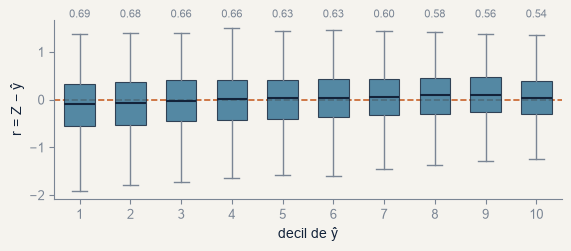

In [100]:
d_oof = resid.loc[resid.periodo == "oof", ["f", "r"]].dropna()
d_oof["decil"] = np.digitize(d_oof["f"], bordes) + 1
datos = [d_oof.loc[d_oof.decil == k, "r"].values for k in deciles]

fig, ax = plt.subplots(figsize=(5.6, 2.4), constrained_layout=True)
bp = ax.boxplot(datos, widths=0.6, showfliers=False, patch_artist=True, whis=(1, 99),
                medianprops=dict(color=TINTA, lw=1.5), whiskerprops=dict(color=GRIS),
                capprops=dict(color=GRIS), boxprops=dict(edgecolor=TINTA, lw=0.8))
for caja in bp["boxes"]:
    caja.set_facecolor(AZUL); caja.set_alpha(0.8)
ax.axhline(0, color=NARANJA, lw=1.2, ls="--", zorder=0)
ytop = ax.get_ylim()[1]
for k, v in zip(deciles, datos):
    ax.text(k, ytop, f"{v.std():.2f}", ha="center", va="bottom", fontsize=8, color=GRIS)
ax.set(xlabel="decil de ŷ", ylabel="r = Z − ŷ", xticks=deciles)
fig.savefig("figuras/ruido_residuo_deciles.png", dpi=200)
plt.show()

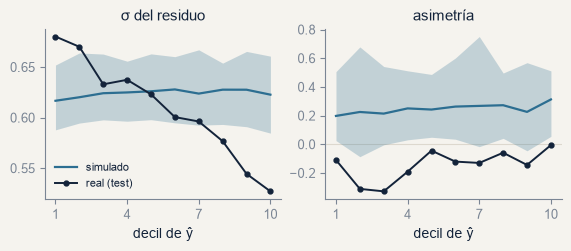

In [101]:
d = pd.DataFrame({"f": f_sim, "r_real": resid["r"].reindex(f_sim.index)})
d["decil"] = np.digitize(d["f"], bordes) + 1
g = r_sims.groupby(d["decil"])

sd_real, sk_real = d.groupby("decil")["r_real"].std(), d.groupby("decil")["r_real"].apply(lambda x: skew(x.dropna()))
sd_sim = g.std()                                        # (decil, sim)
sk_sim = g.agg(lambda x: skew(x))

fig, axs = plt.subplots(1, 2, figsize=(5.6, 2.4), constrained_layout=True, sharex=True)
for ax, real, sim, lab in [(axs[0], sd_real, sd_sim, "σ del residuo"), (axs[1], sk_real, sk_sim, "asimetría")]:
    p5, p50, p95 = np.percentile(sim.values, [5, 50, 95], axis=1)
    ax.fill_between(sim.index, p5, p95, color=AZUL, alpha=0.25, lw=0)
    ax.plot(sim.index, p50, color=AZUL, lw=1.6, label="simulado")
    ax.plot(real.index, real.values, "o-", color=TINTA, lw=1.4, ms=3.5, label="real (test)")
    ax.set(title=lab, xlabel="decil de ŷ", xticks=[1, 4, 7, 10])
axs[1].axhline(0, color="#DDD8CE", lw=0.8, zorder=0)
axs[0].legend(frameon=False, fontsize=8)
fig.savefig("figuras/ruido_sigma_asimetria.png", dpi=200)
plt.show()

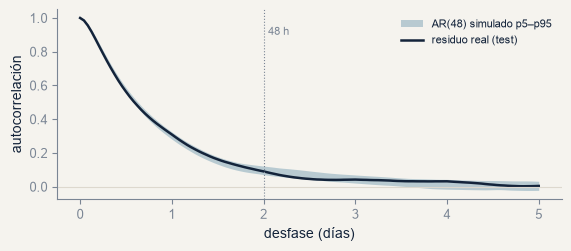

In [102]:
lags = np.arange(0, 121)                                # 5 días
acf_real = acf_h(resid.loc["2016":"2025", "r"], lags)
acf_sim = np.array([acf_h(r_sims[c], lags) for c in r_sims.columns])
p5, p95 = np.percentile(acf_sim, [5, 95], axis=0)

fig, ax = plt.subplots(figsize=(5.6, 2.4), constrained_layout=True)
ax.fill_between(lags / 24, p5, p95, color=AZUL, alpha=0.3, lw=0, label="AR(48) simulado p5–p95")
ax.plot(lags / 24, acf_real, color=TINTA, lw=1.8, label="residuo real (test)")
ax.axhline(0, color="#DDD8CE", lw=0.8)
ax.axvline(2, color=GRIS, lw=0.8, ls=":")
ax.text(2.05, 0.9, "48 h", fontsize=8, color=GRIS)
ax.set(xlabel="desfase (días)", ylabel="autocorrelación")
ax.legend(frameon=False, fontsize=8)
fig.savefig("figuras/ruido_acf.png", dpi=200)
plt.show()

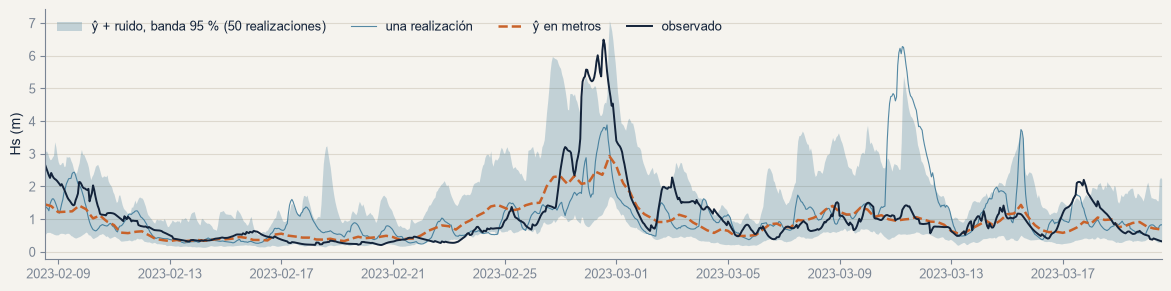

por encima 3.8% | por debajo 4.9%


In [103]:
t_max = hs_obs.idxmax()
t0, t1 = t_max - pd.Timedelta(days=20), t_max + pd.Timedelta(days=20)
w = hs_sims.loc[t0:t1]

fig, ax = plt.subplots(figsize=(11.6, 2.8), constrained_layout=True)
ax.fill_between(w.index, w.quantile(0.025, axis=1), w.quantile(0.975, axis=1), color=AZUL, alpha=0.25, lw=0,
                label="ŷ + ruido, banda 95 % (50 realizaciones)")
ax.plot(w.iloc[:, 0], color=AZUL, lw=0.8, alpha=0.8, label="una realización")
ax.plot(hs_f.loc[t0:t1], color=NARANJA, lw=1.8, ls="--", label="ŷ en metros")
ax.plot(hs_obs.loc[t0:t1], color=TINTA, lw=1.4, label="observado")
ax.set(ylabel="Hs (m)", xlim=(t0, t1))
ax.grid(axis="y", color="#DDD8CE", lw=0.8); ax.set_axisbelow(True)
ax.legend(frameon=False, loc="upper left", ncol=4, fontsize=9)
fig.savefig("figuras/ruido_temporal.png", dpi=200)
plt.show()

#### Cobertura para la tarjeta
q_lo, q_hi = hs_sims.quantile(0.025, axis=1), hs_sims.quantile(0.975, axis=1)
o = hs_obs.reindex(hs_sims.index)
print(f"por encima {(o > q_hi).mean():.1%} | por debajo {(o < q_lo).mean():.1%}")

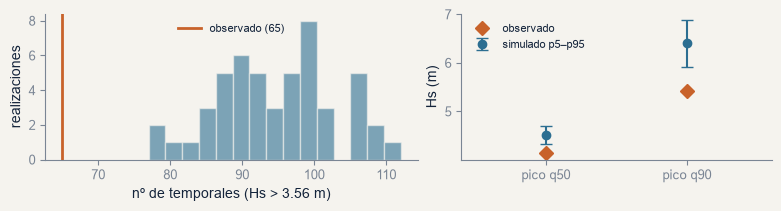

In [104]:
u = hs_obs.quantile(0.99)
picos = lambda s: s.values[find_peaks(s.values, height=u, distance=72)[0]]
p_obs = picos(hs_obs)
p_sim = [picos(hs_sims[c]) for c in hs_sims.columns]

fig, axs = plt.subplots(1, 2, figsize=(7.7, 2.0), constrained_layout=True, gridspec_kw={"width_ratios": [1.2, 1]})
n_sim = [len(p) for p in p_sim]
axs[0].hist(n_sim, bins=15, color=AZUL, alpha=0.6, edgecolor=FONDO)
axs[0].axvline(len(p_obs), color=NARANJA, lw=2, label=f"observado ({len(p_obs)})")
axs[0].set(xlabel=f"nº de temporales (Hs > {u:.2f} m)", ylabel="realizaciones")
axs[0].legend(frameon=False, fontsize=8)

for j, q in enumerate([0.5, 0.9]):
    qs = np.array([np.quantile(p, q) for p in p_sim])
    p5, p50, p95 = np.percentile(qs, [5, 50, 95])
    axs[1].errorbar(j, p50, yerr=[[p50 - p5], [p95 - p50]], fmt="o", color=AZUL, capsize=4, lw=1.5,
                    label="simulado p5–p95" if j == 0 else None)
    axs[1].plot(j, np.quantile(p_obs, q), "D", color=NARANJA, ms=7, label="observado" if j == 0 else None)
axs[1].set_xticks([0, 1], ["pico q50", "pico q90"])
axs[1].set(ylabel="Hs (m)", xlim=(-0.6, 1.6))
axs[1].legend(frameon=False, fontsize=8)
fig.savefig("figuras/ruido_temporales_test.png", dpi=200)
plt.show()